In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.decomposition import PCA
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report

In [2]:
df = pd.read_csv('train.csv')
df.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


In [3]:
df.shape

(171202, 34)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 34 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   SK_ID_CURR                  171202 non-null  int64  
 1   NAME_CONTRACT_TYPE          171202 non-null  object 
 2   CODE_GENDER                 171202 non-null  object 
 3   CNT_CHILDREN                171202 non-null  int64  
 4   AMT_INCOME_TOTAL            171202 non-null  float64
 5   AMT_CREDIT                  171202 non-null  float64
 6   AMT_ANNUITY                 171202 non-null  float64
 7   AMT_GOODS_PRICE             171202 non-null  float64
 8   NAME_INCOME_TYPE            171202 non-null  object 
 9   NAME_EDUCATION_TYPE         171202 non-null  object 
 10  NAME_FAMILY_STATUS          171202 non-null  object 
 11  NAME_HOUSING_TYPE           171202 non-null  object 
 12  REGION_POPULATION_RELATIVE  171202 non-null  float64
 13  DAYS_BIRTH    

In [5]:
df.isnull().sum()

,0
SK_ID_CURR,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0


/tmp/ipykernel_2770/2357265553.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='TARGET', palette='Set2')


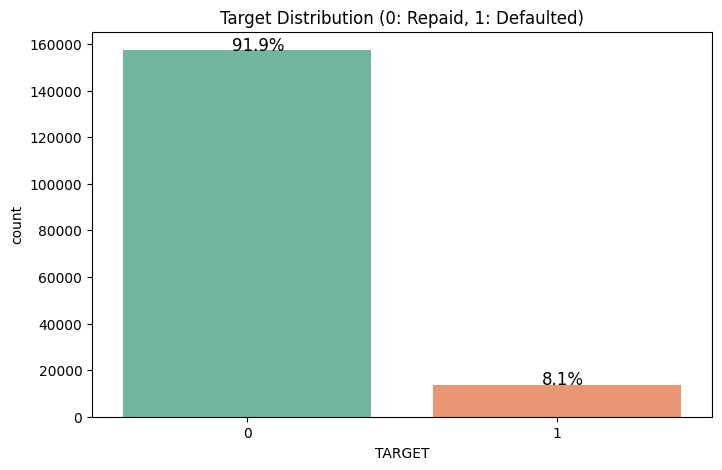

In [6]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='TARGET', palette='Set2')
plt.title('Target Distribution (0: Repaid, 1: Defaulted)')

total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.05
    y = p.get_y() + p.get_height()
    ax.annotate(percentage, (x, y), size=12)

plt.show()

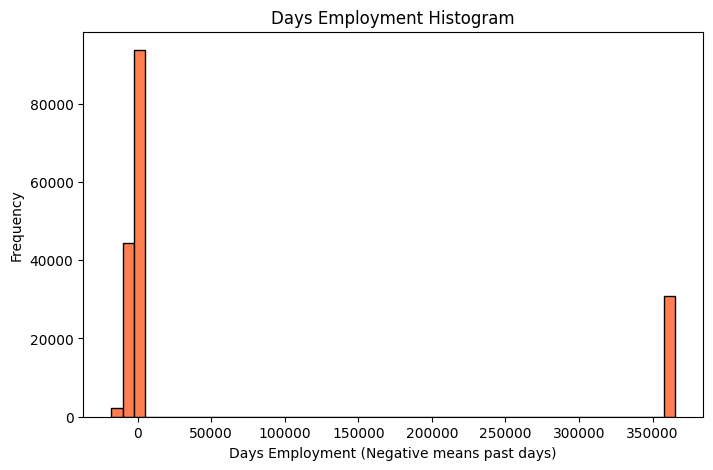

Number of anomalies (365243 days): 30898
Percentage of anomalies: 18.05%


In [7]:
plt.figure(figsize=(8, 5))
df['DAYS_EMPLOYED'].plot.hist(bins=50, color='coral', edgecolor='black')
plt.title('Days Employment Histogram')
plt.xlabel('Days Employment (Negative means past days)')
plt.show()

anomalies_count = (df['DAYS_EMPLOYED'] == 365243).sum()
print(f"Number of anomalies (365243 days): {anomalies_count}")
print(f"Percentage of anomalies: {(anomalies_count / len(df)) * 100:.2f}%")

In [8]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
correlations = df[numeric_cols].corr()['TARGET'].sort_values()

print("--- Top 5 Positive Correlations (Increases risk of default) ---")
print(correlations.tail(6))

print("\n--- Top 5 Negative Correlations (Decreases risk of default) ---")
print(correlations.head(5))

--- Top 5 Positive Correlations (Increases risk of default) ---
FLAG_EMP_PHONE            0.045646
DAYS_ID_PUBLISH           0.052567
DAYS_LAST_PHONE_CHANGE    0.055194
REGION_RATING_CLIENT      0.058984
DAYS_BIRTH                0.079541
TARGET                    1.000000
Name: TARGET, dtype: float64

--- Top 5 Negative Correlations (Decreases risk of default) ---
EXT_SOURCE_3      -0.178317
EXT_SOURCE_2      -0.162562
EXT_SOURCE_1      -0.154050
DAYS_EMPLOYED     -0.044592
AMT_GOODS_PRICE   -0.042035
Name: TARGET, dtype: float64


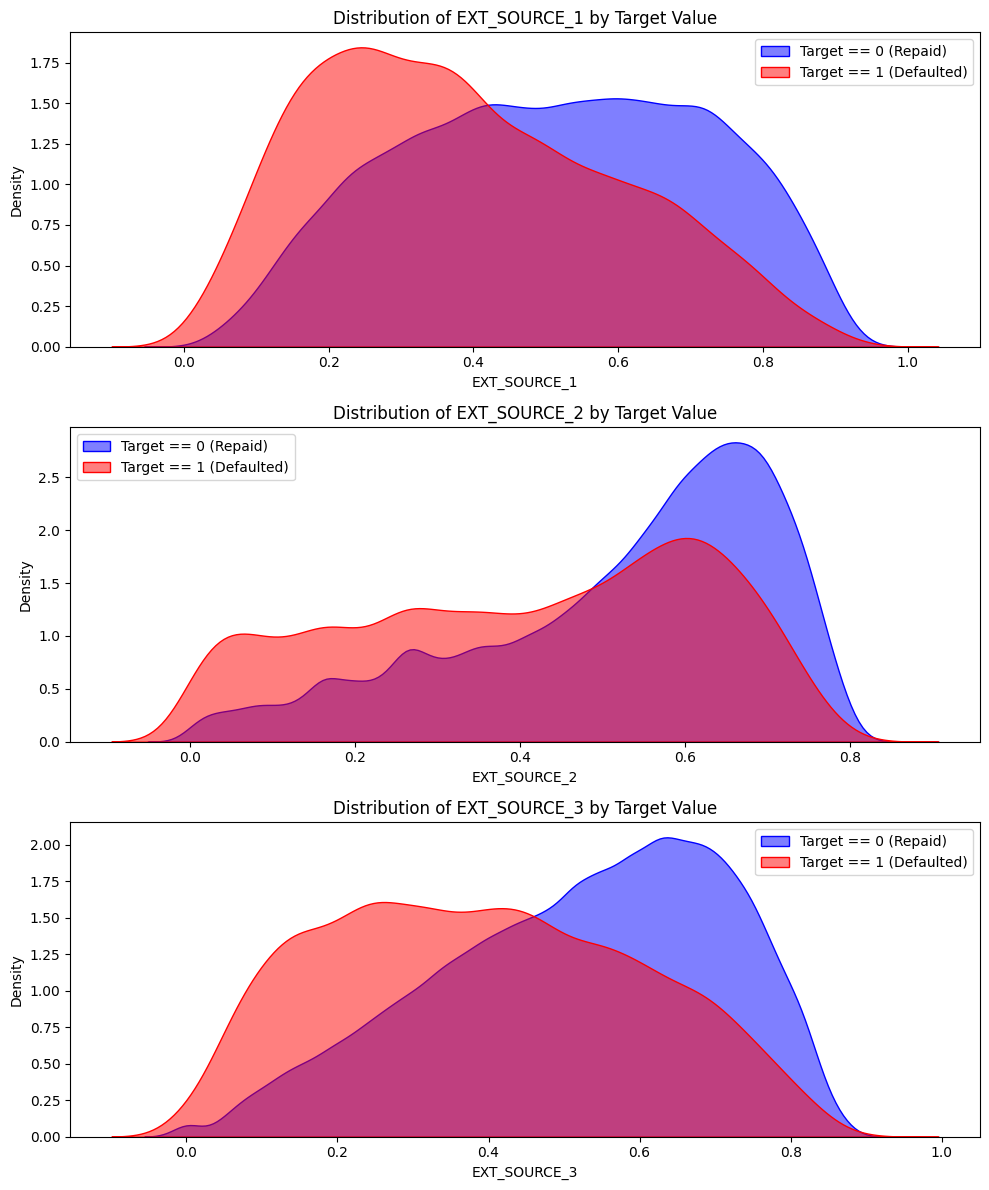

In [9]:
plt.figure(figsize=(10, 12))
for i, source in enumerate(['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']):
    plt.subplot(3, 1, i + 1)
    sns.kdeplot(df.loc[df['TARGET'] == 0, source], label='Target == 0 (Repaid)', fill=True, color='blue', alpha=0.5)
    sns.kdeplot(df.loc[df['TARGET'] == 1, source], label='Target == 1 (Defaulted)', fill=True, color='red', alpha=0.5)
    plt.title(f'Distribution of {source} by Target Value')
    plt.xlabel(source)
    plt.ylabel('Density')
    plt.legend()

plt.tight_layout()
plt.show()

In [10]:
def drop_unnecessary_cols(df):
    df_out = df.copy()
    cols_to_drop = ['SK_ID_CURR', 'FLAG_MOBIL', 'AMT_GOODS_PRICE']
    existing_cols = [col for col in cols_to_drop if col in df_out.columns]
    return df_out.drop(columns=existing_cols)

df_step1 = drop_unnecessary_cols(df)

In [11]:
def handle_missing_values(df):
    df_out = df.copy()
    bureau_cols = [col for col in df_out.columns if 'AMT_REQ_CREDIT_BUREAU' in col]
    for col in bureau_cols:
        df_out[col] = df_out[col].fillna(0)

    if 'OWN_CAR_AGE' in df_out.columns:
        df_out['OWN_CAR_AGE'] = df_out['OWN_CAR_AGE'].fillna(-1)

    if 'CNT_FAM_MEMBERS' in df_out.columns:
        mode_val = df_out['CNT_FAM_MEMBERS'].mode()[0]
        df_out['CNT_FAM_MEMBERS'] = df_out['CNT_FAM_MEMBERS'].fillna(mode_val)

    return df_out

df_step2 = handle_missing_values(df_step1)

In [12]:
def handle_anomalies(df):
    df_out = df.copy()
    if 'DAYS_EMPLOYED' in df_out.columns:
        df_out['DAYS_EMPLOYED_ANOM'] = (df_out['DAYS_EMPLOYED'] == 365243).astype(int)
        df_out['DAYS_EMPLOYED'] = df_out['DAYS_EMPLOYED'].replace({365243: np.nan})

    if 'CODE_GENDER' in df_out.columns:
        df_out['CODE_GENDER'] = df_out['CODE_GENDER'].replace({'XNA': np.nan})

    return df_out

df_step3 = handle_anomalies(df_step2)

In [13]:
def engineer_features_and_split(df):
    df_out = df.copy()

    if 'DAYS_BIRTH' in df_out.columns:
        df_out['AGE_YEARS'] = abs(df_out['DAYS_BIRTH']) / 365
        df_out = df_out.drop(columns=['DAYS_BIRTH'])

    if 'DAYS_EMPLOYED' in df_out.columns:
        df_out['YEARS_EMPLOYED'] = abs(df_out['DAYS_EMPLOYED']) / 365
        df_out = df_out.drop(columns=['DAYS_EMPLOYED'])

    if 'AMT_CREDIT' in df_out.columns and 'AMT_INCOME_TOTAL' in df_out.columns:
        df_out['CREDIT_INCOME_RATIO'] = df_out['AMT_CREDIT'] / df_out['AMT_INCOME_TOTAL']

    if 'AMT_ANNUITY' in df_out.columns and 'AMT_INCOME_TOTAL' in df_out.columns:
        df_out['ANNUITY_INCOME_RATIO'] = df_out['AMT_ANNUITY'] / df_out['AMT_INCOME_TOTAL']

    if 'AMT_CREDIT' in df_out.columns and 'AMT_ANNUITY' in df_out.columns:
        df_out['CREDIT_TERM'] = df_out['AMT_CREDIT'] / df_out['AMT_ANNUITY']

    ext_cols = [c for c in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3'] if c in df_out.columns]
    if ext_cols:
        df_out['EXT_SOURCE_MEAN'] = df_out[ext_cols].mean(axis=1)

    if 'TARGET' in df_out.columns:
        y = df_out['TARGET']
        X = df_out.drop(columns=['TARGET'])
        return X, y
    else:
        return df_out

X_train_full, y_train = engineer_features_and_split(df_step3)

In [14]:
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train, test_size=0.2, random_state=42,stratify=y_train)

In [15]:
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"y_val shape: {y_val.shape}")

X_train shape: (136961, 35)
y_train shape: (136961,)
X_val shape: (34241, 35)
y_val shape: (34241,)


In [16]:
numeric_features = X_train.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

In [17]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
])

In [20]:
clf1 = LogisticRegression(max_iter=1000, random_state=42)
clf2 = RandomForestClassifier(n_estimators=100, max_depth=6, n_jobs=-1, random_state=42)
clf3 = LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, n_jobs=-1, random_state=42)
clf4 = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, n_jobs=-1, eval_metric='auc', random_state=42)

In [21]:
voting_clf = VotingClassifier(
    estimators=[
        ('lr', clf1),
        ('rf', clf2),
        ('lgbm', clf3),
        ('xgb', clf4)
    ],
    voting='soft'
)

In [38]:
pipeline_voting = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42, sampling_strategy=0.5)),
    ('ensemble', voting_clf)
])

In [39]:
print("Training Ensemble Voting Classifier (This will take some time)...")
pipeline_voting.fit(X_train, y_train)

Training Ensemble Voting Classifier (This will take some time)...
[LightGBM] [Info] Number of positive: 62952, number of negative: 125904
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.146636 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 24766
[LightGBM] [Info] Number of data points in the train set: 188856, number of used features: 127
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.333333 -> initscore=-0.693147
[LightGBM] [Info] Start training from score -0.693147


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'REGION_POPULATION_RELATIVE',
                                                   'DAYS_REGISTRATION',
                                                   'DAYS_ID_PUBLISH',
                                                   'OWN_CAR_AGE',
                                                   'FLAG_EMP_PHONE',
                                                   'FLAG_WORK_PHONE',
                                                   'CNT_FAM_M...
                                                             gamma=None,
                                                             grow_policy=None,
                                                             importance_type=None,
                                                             interaction_constraints=None,
                                                             learning_rate=0.05,
                                                             max_bin=None,
                                                             max_cat_threshold=None,
                                                             max_cat_to_onehot=None,
                                                             max_delta_step=None,
                                                             max_depth=6,
                                                             max_leaves=None,
                                                             min_child_weight=None,
                                                             missing=nan,
                                                             monotone_constraints=None,
                                                             multi_strategy=None,
                                                             n_estimators=300,
                                                             n_jobs=-1,
                                                             num_parallel_tree=None, ...))],
                                  voting='soft'))])

In [40]:
y_pred_proba_voting = pipeline_voting.predict_proba(X_val)[:, 1]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [47]:
custom_threshold = 0.25
y_pred_custom_voting = (y_pred_proba_voting >= custom_threshold).astype(int)

In [49]:
auc_score_voting = roc_auc_score(y_val, y_pred_proba_voting)
print(f"\n--- Validation Results (Voting Classifier + SMOTE) ---")
print(f"ROC-AUC Score: {auc_score_voting:.4f}")
print("\nClassification Report (Threshold 0.25):\n", classification_report(y_val, y_pred_custom_voting))


--- Validation Results (Voting Classifier + SMOTE) ---
ROC-AUC Score: 0.7305

Classification Report (Threshold 0.25):
               precision    recall  f1-score   support

           0       0.95      0.78      0.86     31477
           1       0.18      0.54      0.27      2764

    accuracy                           0.76     34241
   macro avg       0.57      0.66      0.56     34241
weighted avg       0.89      0.76      0.81     34241

